# 02. Features and scaling
**Lead: Vaibhav.** Goal: give both models exactly the same numerical inputs.

V1-V28 are anonymized PCA features supplied by the dataset provider. We do not run another PCA here.
Add `log(1 + Amount)` for 29 inputs. Use Time only to split, and leave Class out of the inputs.

In [1]:
from pathlib import Path
import os, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Image

# Find the project even if Jupyter starts inside phase2/notebooks.
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents]
            if (p / "CSAI_Project_Instructions_Phase_1_and_Phase_2.pdf").exists())
P2 = ROOT / "phase2"
for folder in ["results", "figures", "models", "output"]:
    (P2 / folder).mkdir(exist_ok=True)
plt.rcParams.update({"figure.figsize": (8, 4), "font.size": 11,
                     "axes.spines.top": False, "axes.spines.right": False})

def show(name):
    plt.tight_layout()
    plt.savefig(P2 / "figures" / name, dpi=150, bbox_inches="tight")
    display(Image(filename=str(P2 / "figures" / name), width=850))
    plt.close()

In [2]:
from sklearn.preprocessing import StandardScaler
import joblib
parts = {name: pd.read_csv(P2 / "models" / f"{name}.csv")
         for name in ["train", "validation", "test"]}
features = [f"V{i}" for i in range(1, 29)] + ["LogAmount"]
def make_features(frame):
    x = frame[[f"V{i}" for i in range(1, 29)]].copy()
    x["LogAmount"] = np.log1p(frame.Amount)
    return x
normal_train = parts["train"].loc[parts["train"].Class == 0]
scaler = StandardScaler().fit(make_features(normal_train))
X_train = scaler.transform(make_features(normal_train))
X_validation = scaler.transform(make_features(parts["validation"]))
X_test = scaler.transform(make_features(parts["test"]))
y_validation = parts["validation"].Class.to_numpy()
y_test = parts["test"].Class.to_numpy()
assert X_train.shape == (169893, 29)
assert scaler.n_samples_seen_ == len(normal_train)
assert "Class" not in features and "Time" not in features
assert all(np.isfinite(x).all() for x in [X_train, X_validation, X_test])
# A direct check that we preserved Phase 1's model inputs and row order.
old = np.load(ROOT / "phase1/data/processed/features.npz") if (ROOT / "phase1/data/processed/features.npz").exists() else None
if old is not None:
    for key, value in [("X_train", X_train), ("X_validation", X_validation), ("X_test", X_test)]:
        assert np.allclose(old[key], value)
    assert np.array_equal(old["y_test"], y_test)
np.savez_compressed(P2 / "models/features.npz", X_train=X_train,
                    X_validation=X_validation, X_test=X_test,
                    y_validation=y_validation, y_test=y_test)
joblib.dump(scaler, P2 / "models/scaler.joblib")
(P2 / "results/features.json").write_text(json.dumps(features, indent=2))
display(pd.DataFrame({"set": ["Legitimate training", "Mixed validation", "Mixed test"],
                      "rows": [len(X_train), len(X_validation), len(X_test)], "features": 29}))

,set,rows,features
0,Legitimate training,169893,29
1,Mixed validation,56745,29
2,Mixed test,56746,29


## Why these steps?
`log1p` compresses unusually large amounts. Example: 9 becomes 2.30 and 999 becomes 6.91.
Standardization subtracts the normal-training mean and divides by its standard deviation.
This stops a large-unit feature dominating reconstruction error simply because of its units.

**Fit** learns the mean and standard deviation. **Transform** applies the saved values.
Fitting on test data would let future information influence training.
No clipping is applied: extreme values remain visible to both models.

Mean after scaling (first 5): [-0. -0. -0.  0.  0.]
Standard deviation (first 5): [1. 1. 1. 1. 1.]


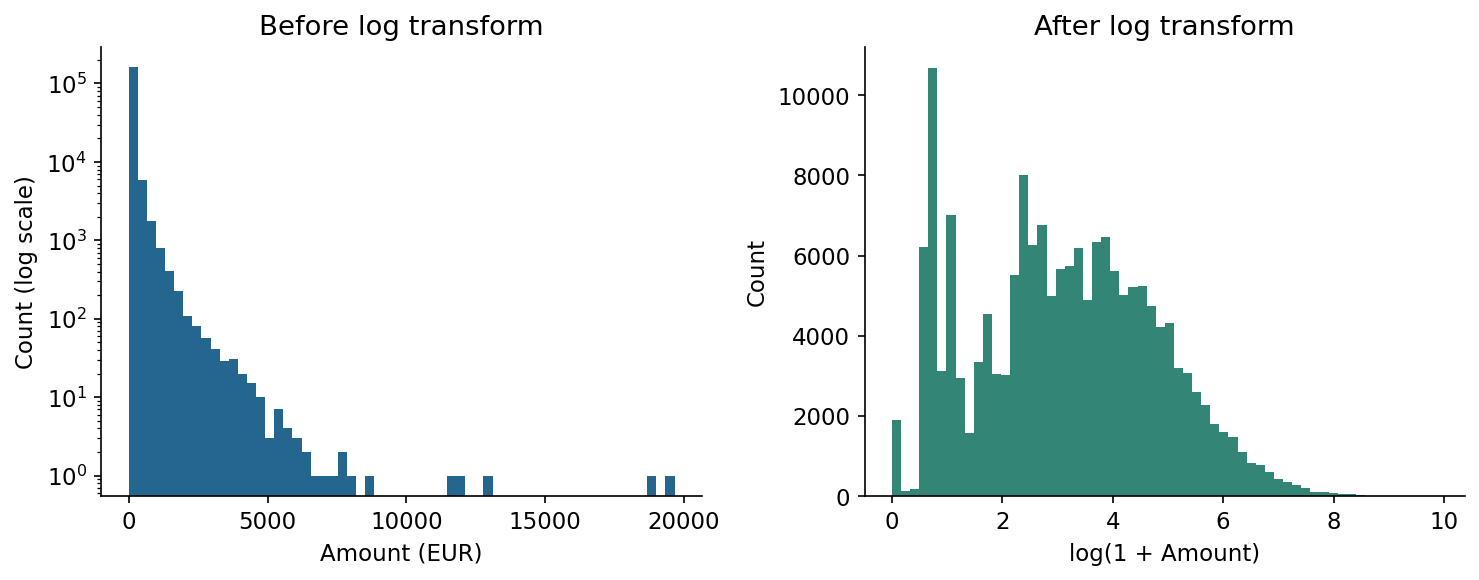

In [3]:
fig, ax = plt.subplots(1, 2, figsize=(10, 4))
ax[0].hist(normal_train.Amount, bins=60, color="#24668d")
ax[0].set_yscale("log")
ax[0].set_xlabel("Amount (EUR)"); ax[0].set_ylabel("Count (log scale)")
ax[0].set_title("Before log transform")
ax[1].hist(np.log1p(normal_train.Amount), bins=60, color="#338575")
ax[1].set_xlabel("log(1 + Amount)"); ax[1].set_ylabel("Count")
ax[1].set_title("After log transform")
show("02_features.png")
print("Mean after scaling (first 5):", np.round(X_train.mean(axis=0)[:5], 5))
print("Standard deviation (first 5):", np.round(X_train.std(axis=0)[:5], 5))

**Say in the viva:** The label filters legitimate training rows but is never a network input.
Training is often called one-class or semi-supervised anomaly detection because known legitimate labels
are needed to create the training subset. The reconstruction objective itself uses no fraud targets.